# Walking speed and gait-phase estimation

This is an extension of our German shepherd / virtual-IMU notebook. We keep the same measured reference and the same right-leg half-cycle offset.

The key identity is the chain rule:

$$\omega(t)=\frac{d\beta}{dt}=\frac{d\beta}{ds}\frac{ds}{dt}.$$

If the dog walks at $u$ times the reference cadence, then $\omega_\mathrm{expected}(s,u)=u\,\omega_\mathrm{ref}(s)$. Only one number, $u$, needs to be updated; we do not generate hundreds of reference curves.


## Data and setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML

plt.rc('font', family='serif', size=10)
plt.rc('text', usetex=True)

# Same CSV and preprocessing as our previous notebook.
df = pd.read_csv('dog_positions.csv')
df.columns = df.columns.str.strip()
frames = df['Frame'].to_numpy()
for color in ['Blue', 'Red', 'Yellow', 'Green']:
    for axis in 'XY':
        name = color + axis
        df[name] = df[name].rolling(3, center=True, min_periods=1).median()
        df[name] = df[name].rolling(3, center=True, min_periods=1).mean()

points = {}
for color in ['Red', 'Yellow', 'Green']:
    points[color] = np.column_stack((
        df[color+'X'] - df['BlueX'], df['BlueY'] - df[color+'Y']
    ))
angle = np.deg2rad(1)  # rough correction for the image tilt
rot = np.array([[np.cos(angle), -np.sin(angle)],
                [np.sin(angle),  np.cos(angle)]])
points = {name: xy @ rot.T for name, xy in points.items()}
scale = np.median(np.linalg.norm(points['Yellow']-points['Red'], axis=1))
elbow, wrist, toe = [points[c]/scale for c in ['Red', 'Yellow', 'Green']]
L1 = np.median(np.linalg.norm(elbow, axis=1))
L2 = 1.0
L3 = np.median(np.linalg.norm(toe-wrist, axis=1))

# Two measured strides; phase is dimensionless (0 to 1).
cycle_bounds = [(11, 29), (29, 50)]
phase_grid = np.linspace(0, 1, 160, endpoint=False)
period_frames = np.mean([b-a for a, b in cycle_bounds])

def cycle_average(values):
    return np.mean([
        np.interp(a+(b-a)*phase_grid, frames, values)
        for a, b in cycle_bounds
    ], axis=0)

def smooth_periodic(values):
    return (np.roll(values, 2) + 2*np.roll(values, 1) + 3*values
            + 2*np.roll(values, -1) + np.roll(values, -2))/9

def ref(values, phase):
    return np.interp(np.asarray(phase) % 1,
                     np.r_[phase_grid, 1], np.r_[values, values[0]])

# Absolute segment orientations, calculated from the measured landmarks.
upper = np.unwrap(np.arctan2(elbow[:, 1], elbow[:, 0]))
forearm = np.unwrap(np.arctan2((wrist-elbow)[:, 1], (wrist-elbow)[:, 0]))
paw = np.unwrap(np.arctan2((toe-wrist)[:, 1], (toe-wrist)[:, 0]))
upper_ref = smooth_periodic(cycle_average(upper))
fore_ref = smooth_periodic(cycle_average(forearm))
paw_ref = smooth_periodic(cycle_average(paw))
print(f'Normalized lengths: {L1:.3f}, {L2:.3f}, {L3:.3f}')


Normalized lengths: 0.858, 1.000, 0.539


In [2]:
# Periodic measured reference. We keep the same 3-link IK for the prosthesis.
# For visualization, the upper two links follow measured segment directions.
def measured_leg(s):
    a1, a2, a3 = ref(upper_ref, s), ref(fore_ref, s), ref(paw_ref, s)
    ex, ey = L1*np.cos(a1), L1*np.sin(a1)
    wx, wy = ex + L2*np.cos(a2), ey + L2*np.sin(a2)
    tx, ty = wx + L3*np.cos(a3), wy + L3*np.sin(a3)
    return np.array([ex, ey]), np.array([wx, wy]), np.array([tx, ty])

# Ideal angular velocity for the reference cadence, in rad/recorded frame.
# A central difference on the periodic phase curve gives d(beta)/ds.
dbeta_ds = (np.roll(fore_ref, -1)-np.roll(fore_ref, 1))/(2/len(phase_grid))
omega_ref = dbeta_ds/period_frames

# Existing kinematic idea: paw target (x,y,phi) -> three joint angles.
def inverse_kinematics_3link(x, y, phi, L1, L2, L3):
    xw, yw = x-L3*np.cos(phi), y-L3*np.sin(phi)
    c2 = (xw*xw+yw*yw-L1*L1-L2*L2)/(2*L1*L2)
    if np.any(np.abs(c2)>1+1e-8):
        raise ValueError('Unreachable target')
    c2 = np.clip(c2, -1, 1)
    s2 = np.sqrt(1-c2*c2)
    theta2 = np.arctan2(s2, c2)
    theta1 = np.arctan2(yw, xw)-np.arctan2(L2*s2, L1+L2*c2)
    return np.array([theta1, theta2, phi-theta1-theta2])

def command_angles(s):
    _, _, T = measured_leg(s)
    return inverse_kinematics_3link(T[0], T[1], ref(paw_ref, s), L1, L2, L3)


## Model / experiment

In [3]:
# Synthesize one dog walking at *changing cadence* along the measured reference.
# This is a replay-speed test, NOT new video data or proof about real acceleration.
rng = np.random.default_rng(11)
n_steps = 220
samples = np.arange(n_steps)
speed_true = np.interp(samples, [0, 35, 70, 112, 145, 175, 219],
                       [0.65, 0.65, 1.4, 1.4, 0.85, 0.5, 0.5])
phase_true = np.zeros(n_steps)
phase_true[0] = 0.16
for i in range(1, n_steps):
    phase_true[i] = (phase_true[i-1] + speed_true[i-1]/period_frames) % 1

# Virtual forearm IMU: angle and angular velocity; small illustrative noise.
beta_measured = ref(fore_ref, phase_true) + rng.normal(0, np.deg2rad(0.8), n_steps)
omega_measured = (ref(omega_ref, phase_true)*speed_true
                  + rng.normal(0, np.deg2rad(0.8), n_steps))


In [4]:
# Phase lookup + temporal continuity. The only new estimated state is speed u.
def estimate_phase(adaptive_speed=False):
    phase = np.zeros(n_steps)
    estimated_speed = np.ones(n_steps)
    u = 1.0
    angle_scale = max(np.std(fore_ref), 0.07)
    omega_scale = max(np.std(omega_ref), 0.035)

    for i in range(n_steps):
        # Chain rule: at cadence multiplier u, omega_expected = u * omega_ref.
        score = ((beta_measured[i]-fore_ref)/angle_scale)**2
        score += ((omega_measured[i]-u*omega_ref)/omega_scale)**2

        if i > 0:
            expected = (phase[i-1]+u/period_frames) % 1
            difference = (phase_grid-expected+0.5) % 1-0.5
            score += 0.02*(difference/(u/period_frames))**2

        phase[i] = phase_grid[np.argmin(score)]

        if adaptive_speed:
            # Infer ONE cadence factor from observed/expected angular velocity.
            local_omega = ref(omega_ref, phase[i])
            if abs(local_omega) > 0.055 and omega_measured[i]*local_omega > 0:
                candidate = np.clip(omega_measured[i]/local_omega, 0.35, 1.9)
                u = 0.88*u + 0.12*candidate  # modest smoothing
        estimated_speed[i] = u

    return phase, estimated_speed

phase_fixed, speed_fixed = estimate_phase(False)
phase_adaptive, speed_adaptive = estimate_phase(True)

def circular_error(est):
    return (est-phase_true+0.5) % 1-0.5

for name, est in [('Fixed cadence', phase_fixed), ('Adaptive cadence', phase_adaptive)]:
    print(f'{name}: phase RMSE {np.sqrt(np.mean(circular_error(est)**2)):.4f} cycles')
print(f'Estimated cadence RMSE: {np.sqrt(np.mean((speed_adaptive-speed_true)**2)):.3f}x')

# Same hypothetical contralateral 0.5-cycle offset for the right prosthesis.
right_true = command_angles((phase_true+0.5) % 1)
right_fixed = command_angles((phase_fixed+0.5) % 1)
right_adaptive = command_angles((phase_adaptive+0.5) % 1)


Fixed cadence: phase RMSE 0.0212 cycles
Adaptive cadence: phase RMSE 0.0104 cycles
Estimated cadence RMSE: 0.157x


## Results

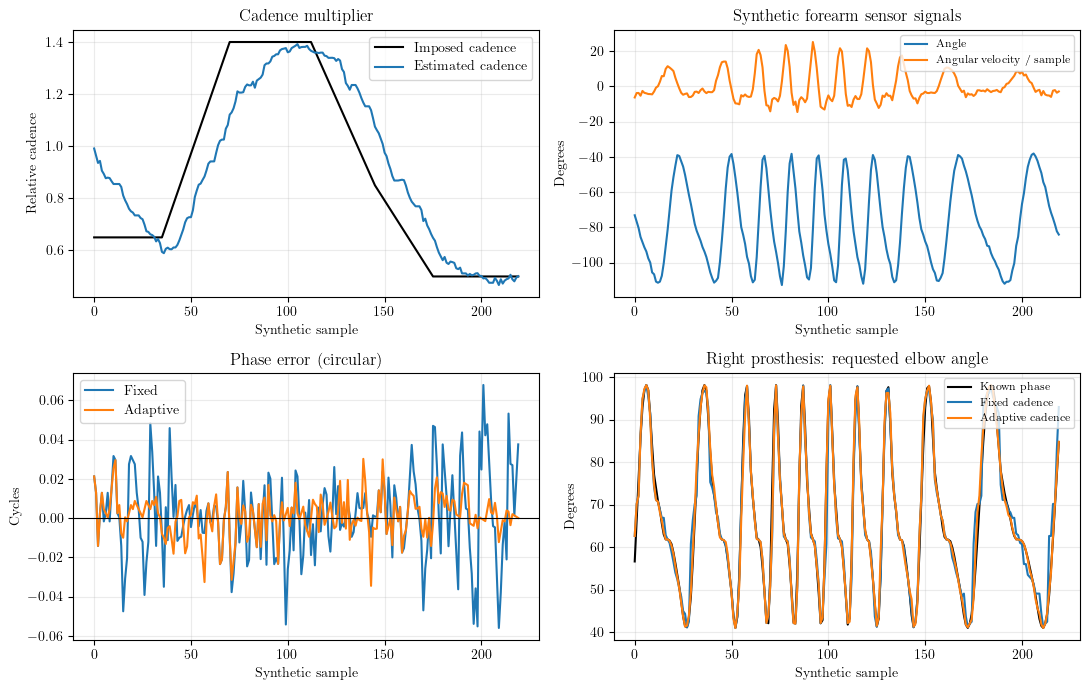

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(samples, speed_true, 'k', label='Imposed cadence')
axes[0, 0].plot(samples, speed_adaptive, label='Estimated cadence')
axes[0, 0].set(title='Cadence multiplier', xlabel='Synthetic sample', ylabel='Relative cadence')
axes[0, 0].legend()

axes[0, 1].plot(samples, np.rad2deg(beta_measured), label='Angle')
axes[0, 1].plot(samples, np.rad2deg(omega_measured), label='Angular velocity / sample')
axes[0, 1].set(title='Synthetic forearm sensor signals', xlabel='Synthetic sample', ylabel='Degrees')
axes[0, 1].legend(fontsize=8)

axes[1, 0].plot(samples, circular_error(phase_fixed), label='Fixed')
axes[1, 0].plot(samples, circular_error(phase_adaptive), label='Adaptive')
axes[1, 0].axhline(0, color='k', lw=0.8)
axes[1, 0].set(title='Phase error (circular)', xlabel='Synthetic sample', ylabel='Cycles')
axes[1, 0].legend()

axes[1, 1].plot(samples, np.rad2deg(right_true[1]), 'k', label='Known phase')
axes[1, 1].plot(samples, np.rad2deg(right_fixed[1]), label='Fixed cadence')
axes[1, 1].plot(samples, np.rad2deg(right_adaptive[1]), label='Adaptive cadence')
axes[1, 1].set(title='Right prosthesis: requested elbow angle',
               xlabel='Synthetic sample', ylabel='Degrees')
axes[1, 1].legend(fontsize=8)
for ax in axes.flat: ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig('walking_speed_diagnostics.png', dpi=150)
plt.show()


## Animation

In [6]:
# Compare two controllers using the SAME virtual sensor inputs.
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharex=True, sharey=True)
lines = []
for ax, title in zip(axes, ['Fixed cadence assumption', 'Adaptive cadence']):
    ax.set(title=title, xlim=(-1.8, 1.3), ylim=(-2.15, 0.2))
    ax.set_aspect('equal')
    ax.grid(alpha=0.2)
    red, = ax.plot([], [], 'o-', color='tab:red', lw=2.5, ms=4, label='Left: reference')
    blue, = ax.plot([], [], 'o-', color='tab:blue', lw=2.5, ms=4, label='Right: estimated')
    ideal, = ax.plot([], [], 'k--', lw=1.2, alpha=.55, label='Right: known phase')
    ax.legend(fontsize=8, loc='lower right')
    lines.append((red, blue, ideal))

def from_angles(a):
    t1, t2, t3 = a
    E = np.array([L1*np.cos(t1), L1*np.sin(t1)])
    W = E + L2*np.array([np.cos(t1+t2), np.sin(t1+t2)])
    T = W + L3*np.array([np.cos(t1+t2+t3), np.sin(t1+t2+t3)])
    return [0, E[0], W[0], T[0]], [0, E[1], W[1], T[1]]

def set_frame(j):
    i = 2*j  # fewer rendered frames keeps the GIF small
    E, W, T = measured_leg(phase_true[i])
    left = ([0, E[0], W[0], T[0]], [0, E[1], W[1], T[1]])
    out = []
    for ang, (red, blue, ideal) in zip([right_fixed, right_adaptive], lines):
        red.set_data(*left)
        blue.set_data(*from_angles(ang[:, i]))
        ideal.set_data(*from_angles(right_true[:, i]))
        out += [red, blue, ideal]
    return out

plt.tight_layout()
anim = FuncAnimation(fig, set_frame, frames=n_steps//2, interval=1000/15, blit=True)
plt.close(fig)
HTML(anim.to_jshtml())


In [7]:
anim.save('walking_speed_comparison.gif', writer=PillowWriter(fps=15))
print('Saved walking_speed_comparison.gif')

Saved walking_speed_comparison.gif


## Interpretation

- Fixed cadence uses $u=1$. Adaptive cadence estimates the multiplier $u$, using the ratio of measured to expected angular velocities where the reference velocity is not close to zero. This is preferable to a search over hundreds of speeds.
- Temporal continuity still helps, but using an incorrect fixed cadence can bias the expected next phase. Increasing the continuity penalty indefinitely would make that worse.
- This is a controlled replay-speed test. Real changes of walking speed can alter the shape of the gait, not only its timing. Here we assume a simplified model where the shape doesn't change.
